# 03 · Modelos de ML clásico (CRISP-DM fase 4)

**Objetivo:** analizar los cuatro modelos clásicos entrenados sobre las 418 características manuales: la búsqueda de hiperparámetros, el sobreajuste, qué características usan y el experimento de control del fondo.

Los modelos se entrenan con `python -m src.training.train_ml` (búsqueda en rejilla con validación cruzada agrupada de 5 pliegues, ~30 min en CPU). Este notebook **no reentrena**: carga los resultados de `experiments/results/` y los modelos de `experiments/checkpoints/`.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils.paths import RESULTS, CHECKPOINTS
from src.utils import plotting
from src.features.handcrafted import feature_names
plotting.setup()
NAMES = {"logreg": "Reg. logística", "svm": "SVM-RBF", "rf": "Random Forest", "xgb": "XGBoost"}
M = {m: json.load(open(RESULTS / f"metrics_{m}.json")) for m in [*NAMES, "logreg_background", "rf_background"]}

## 1. Búsqueda de hiperparámetros

`GridSearchCV` con `StratifiedGroupKFold(5)`: cada pliegue de validación contiene ráfagas completas que no aparecen en el pliegue de entrenamiento. Métrica: F1-macro de 12 clases.

In [2]:
for m in NAMES:
    cv = pd.read_csv(RESULTS / f"cv_{m}.csv")
    cols = [c for c in cv if c.startswith("param_")] + ["mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"]
    print(f"\n== {NAMES[m]}  (mejor: {M[m]['best_params']})")
    print(cv[cols].rename(columns=lambda c: c.replace("param_", "").replace("clf__", "")).round(3).to_string(index=False))


== Reg. logística  (mejor: {'clf__C': 0.1})
   C  mean_test_score  std_test_score  mean_train_score  mean_fit_time
0.01            0.777           0.036             0.950          2.162
0.10            0.791           0.026             0.991          2.517
1.00            0.789           0.025             1.000          2.507

== SVM-RBF  (mejor: {'clf__C': 100, 'clf__gamma': 0.001})
  C gamma  mean_test_score  std_test_score  mean_train_score  mean_fit_time
  1 scale            0.803           0.035             0.993         51.120
  1 0.001            0.805           0.038             0.970         42.293
 10 scale            0.811           0.036             1.000         50.331
 10 0.001            0.823           0.035             1.000         32.899
100 scale            0.811           0.036             1.000         43.943
100 0.001            0.823           0.035             1.000         27.115

== Random Forest  (mejor: {'max_features': 0.1, 'min_samples_leaf': 1})
max_fea

- En todos los modelos las configuraciones difieren en ≤ 2 puntos de F1, menos que la desviación entre pliegues (≈ 3 puntos): **la familia de modelo pesa más que el ajuste fino**.
- La regresión logística mejora al regularizar ($C = 0{,}1$ frente a $C = 1$): con 418 características y ~8.000 imágenes, el modelo sin regularizar ya memoriza (F1 train = 1,0).
- La SVM prefiere $\gamma = 10^{-3}$ (kernel más suave que `scale`) con $C$ alto: frontera flexible pero no demasiado local.
- En RF, usar el 10 % de las características por corte (≈ 42) supera a $\sqrt{d} \approx 20$: los árboles necesitan ver suficientes características de color a la vez.

## 2. Desempeño y sobreajuste

In [3]:
rows = []
for m, name in NAMES.items():
    r = M[m]
    rows.append({"modelo": name, "F1 train": r["train"]["joint_f1_macro"], "F1 CV": r["cv_f1_macro"],
                 "F1 val": r["val"]["joint_f1_macro"], "F1 test": r["test"]["joint_f1_macro"],
                 "acc. calidad test": r["test"]["quality_accuracy"], "AUC calidad": r["test"]["quality_roc_auc"],
                 "acc. fruta test": r["test"]["fruit_accuracy"], "ms/img (modelo)": r["test"]["ms_per_image"]})
tab = pd.DataFrame(rows).set_index("modelo")
tab["brecha train−test"] = tab["F1 train"] - tab["F1 test"]
tab.round(3)

,F1 train,F1 CV,F1 val,F1 test,acc. calidad test,AUC calidad,acc. fruta test,ms/img (modelo),brecha train−test
modelo,,,,,,,,,
Reg. logística,0.986,0.791,0.842,0.847,0.942,0.982,0.872,0.003,0.139
SVM-RBF,1.000,0.823,0.882,0.891,0.952,0.990,0.924,1.214,0.109
Random Forest,1.000,0.854,0.869,0.905,0.953,0.994,0.919,0.046,0.095
XGBoost,1.000,0.861,0.883,0.912,0.965,0.995,0.936,0.015,0.088


- **Todos sobreajustan** en el sentido de que alcanzan F1 ≈ 1 en train; lo que importa es la brecha con datos no vistos. XGBoost tiene la menor brecha (≈ 0,09) y el mejor F1 en test, y la regresión logística la mayor (≈ 0,14).
- **El F1 de test es algo mayor que el de validación y que el de CV** en todos los modelos. No es fuga (la partición está verificada sin ráfagas compartidas): el conjunto de prueba resultó un poco más fácil, porque con particiones agrupadas cada conjunto recibe sesiones completas. Por eso las conclusiones se apoyan en val y en los intervalos de confianza de la fase 5, no en una sola cifra.
- Separar **calidad** (buena/mala) es más fácil que la tarea conjunta: 94–97 % de exactitud y AUC ≥ 0,98. La exactitud de fruta (87–94 %) es menor que la de calidad: la mayoría de los errores conjuntos son confusiones entre frutas parecidas (manzana ↔ granada, guayaba ↔ manzana/naranja; ver la matriz de confusión en la fase 5).

## 3. ¿Qué características usa el mejor modelo clásico?

Importancia por ganancia de XGBoost, agregada por bloque de características.

,importancia total,n,importancia media por característica
bloque,,,
HOG,0.493,324,0.002
LBP,0.162,28,0.006
hist. HSV,0.129,34,0.004
GLCM,0.101,12,0.008
momentos Lab,0.064,9,0.007
momentos HSV,0.042,9,0.005
oscuro/marrón,0.009,2,0.005


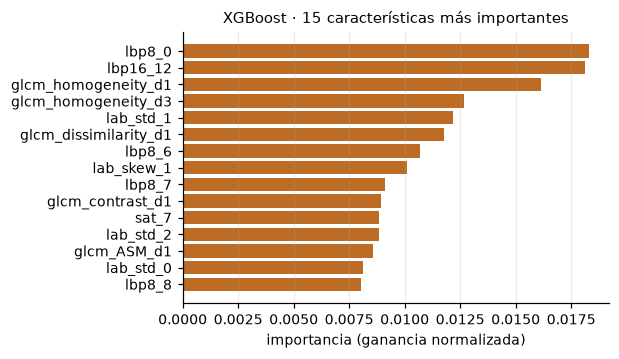

In [4]:
xgb = joblib.load(CHECKPOINTS / "xgb.joblib")
est = xgb.steps[-1][1] if hasattr(xgb, "steps") else xgb
names = np.array(feature_names())
imp = est.feature_importances_
block = pd.Series(names).str.extract(r"^(hue|sat|val|hsv|lab|dark|brown|lbp|glcm|hog)")[0].fillna("otro")
block = block.replace({"hue": "hist. HSV", "sat": "hist. HSV", "val": "hist. HSV", "hsv": "momentos HSV",
                       "lab": "momentos Lab", "dark": "oscuro/marrón", "brown": "oscuro/marrón",
                       "lbp": "LBP", "glcm": "GLCM", "hog": "HOG"})
agg = pd.DataFrame({"bloque": block, "imp": imp}).groupby("bloque").imp.agg(["sum", "size"])
agg["importancia media por característica"] = agg["sum"] / agg["size"]
agg = agg.rename(columns={"sum": "importancia total", "size": "n"}).sort_values("importancia total", ascending=False)
display(agg.round(3))
top = pd.Series(imp, index=names).nlargest(15)[::-1]
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.barh(top.index, top.values, color=plotting.MODEL_COLORS["xgb"])
ax.set_xlabel("importancia (ganancia normalizada)")
ax.set_title("XGBoost · 15 características más importantes")
ax.grid(axis="y", visible=False)
plotting.save(fig, "ml_importancia_xgb")

Por bloques, HOG suma casi la mitad de la importancia total, pero porque son 324 características: **por característica**, las más útiles son GLCM, los momentos de color en Lab y LBP (≈ 3–4 veces más que una de HOG). En conjunto, la textura (LBP + GLCM: 26 %) y el color (histogramas + momentos + oscuro/marrón: 24 %) pesan lo mismo que toda la forma. Es coherente con el problema: la podredumbre cambia el color y la microtextura de la cáscara, y la forma ayuda sobre todo a reconocer **qué** fruta es.

## 4. Control: ¿cuánto se puede acertar mirando solo el fondo?

Se entrenaron los mismos modelos con 54 características de color calculadas **solo en un anillo de 16 px del borde** de la imagen (donde casi siempre hay fondo, no fruta). Si el fondo no tuviera información, la exactitud de calidad sería ≈ 50 %.

In [5]:
bg = pd.DataFrame({name: {"F1 conjunto test": M[m]["test"]["joint_f1_macro"],
                           "acc. calidad val": M[m]["val"]["quality_accuracy"],
                           "acc. calidad test": M[m]["test"]["quality_accuracy"]}
                    for m, name in [("logreg_background", "Reg. log. · solo fondo"), ("rf_background", "RF · solo fondo"),
                                    ("rf", "RF · imagen completa"), ("xgb", "XGBoost · imagen completa")]}).T
bg.round(3)

,F1 conjunto test,acc. calidad val,acc. calidad test
Reg. log. · solo fondo,0.615,0.821,0.833
RF · solo fondo,0.778,0.854,0.904
RF · imagen completa,0.905,0.949,0.953
XGBoost · imagen completa,0.912,0.957,0.965


**Hallazgo crítico.** Un Random Forest que **solo ve el borde** acierta la calidad en el 85 % (val) y el 90 % (test) de las imágenes. El dataset tiene un **sesgo de fondo**: las frutas buenas y malas se fotografiaron, en buena parte, sobre fondos o en sesiones distintas. La imagen completa aporta 5–6 puntos sobre ese piso, que es lo que el modelo realmente aprende de la fruta.

Consecuencias:
1. Las métricas del dataset **sobrestiman** el desempeño en fotos nuevas. La validación con fotos propias (fondos distintos) es imprescindible.
2. En la fase 5 se mide con Grad-CAM cuánta atención pone la CNN en el borde.
3. El protocolo de captura de la app pide fondo liso y uniforme, y el aumento de datos de la CNN (recortes, rotaciones) busca reducir la dependencia del fondo.